<a href="https://colab.research.google.com/github/evgeny-kolonsky/Lab4/blob/main/PE/2026.11/DIY/Lab4_PE_RCA929_DYI_newLEDs.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Photoelectric effect



# Resume



In [1]:
import numpy as np
import requests
import matplotlib.pyplot as plt
from scipy.stats import linregress
from scipy.optimize import curve_fit
from scipy.constants import h, elementary_charge as e, speed_of_light as c
from urllib import request
!wget -q https://raw.githubusercontent.com/tphlabs/data/refs/heads/main/Lab4_SP/spectrumplots.py -O spectrumplots.py -q
from spectrumplots import wavelength_to_color

## Auxillary functions

In [26]:
def find_root2(V, I, *,
              noise_k=10.0,
              r2_min=0.995,
              min_points=3,
              trim_right=0,
              return_diagnostics=False):
    """
    Stopping voltage V0 by the Du Bridge method, fitting the LINEAR segment
    of sqrt(cathode current) and extrapolating to zero.

    Strategy (grows the window from V=0 leftward):
      1. baseline = anode + dark + leakage, fitted where cathode is off
         (V <= anode_Vmax) and subtracted -> R = cathode current.
      2. On the retarding side (V<0, cathode on), walk from the point
         nearest V=0 toward more negative V, adding points one at a time.
         Keep the LONGEST window whose linear fit of sqrt(R) vs V still has
         R^2 >= r2_min. This stops automatically when the thermal foot
         (left bend) starts to spoil the straight line.
      3. Optionally drop `trim_right` points nearest V=0 first, to discard
         the saturation / space-charge bend at the right end.
      4. V0 = x-intercept of that linear segment (foot is never used).

    No spectrum and no Fowler-DuBridge model required -- one rule:
    "fit the line where it is straight, extrapolate to zero."

    Parameters
    ----------
    noise_k    : cathode counts as "on" when R > noise_k * baseline scatter.
    r2_min     : linearity threshold for growing the window.
    min_points : smallest acceptable linear segment.
    trim_right : how many points nearest V=0 to skip (saturation bend).
    """
    V = np.asarray(V, float); I = np.asarray(I, float)
    order = np.argsort(V); V, I = V[order], I[order]

    base = V <= ANODE_VMAX
    if base.sum() < 3:
        return (np.nan, {"reason": "no baseline region; extend sweep"}) \
            if return_diagnostics else np.nan
    lr = linregress(V[base], I[base])
    R = I - (lr.slope * V + lr.intercept)
    noise = np.std(R[base])

    on = (R > noise_k * noise) & (V < NORMPOINT) & (V > ANODE_VMAX)
    if on.sum() < min_points + trim_right:
        return (np.nan, {"reason": "too few cathode points", "baseline": lr}) \
            if return_diagnostics else np.nan

    xv = V[on]; yv = np.sqrt(R[on])
    # sort from V=0 (right) toward negative (left)
    idx = np.argsort(xv)[::-1]
    xs, ys = xv[idx], yv[idx]
    if trim_right:
        xs, ys = xs[trim_right:], ys[trim_right:]

    # grow window from the right; keep the longest with R^2 >= r2_min
    best_n, best_fit = 0, None
    for n in range(min_points, len(xs) + 1):
        f = linregress(xs[:n], ys[:n])
        if f.rvalue**2 >= r2_min:
            best_n, best_fit = n, f
        # once it has been good and then drops, we can stop early
        elif best_n >= min_points and f.rvalue**2 < r2_min:
            break
    if best_fit is None:                       # never linear enough -> longest run
        best_n = len(xs); best_fit = linregress(xs, ys)

    V0 = -best_fit.intercept / best_fit.slope
    if return_diagnostics:
        seg = idx[trim_right: trim_right + best_n]
        return V0, {"anode_fit": lr, "noise": noise, "cathode_current": R,
                    "cathode_mask": on, "fit_x": xs[:best_n], "fit_y": ys[:best_n],
                    "cathode_fit": best_fit, "r2": best_fit.rvalue**2, "best_n": best_n,
                    "xv": xv, "yv":yv}
    return V0


def get_observed_by_nominal(wl):
  data = '''
  # wl_nominal[nm] peak[nm] FWHM[nm]
  395  398 16
  405  401 12
  460  469 22
  470  448 16
  525  529 16
  590  590 14
  640  650 20
  624  621 16
  '''
  wl_nominal, wl_observed, fwhm = np.genfromtxt(data.splitlines()).T
  err = fwhm / 2
  mask = (wl == wl_nominal)
  return wl_observed[mask][0], err[mask][0]

# Example
get_observed_by_nominal(460)

(np.float64(469.0), np.float64(11.0))

#Volt-ampere curve


(0.0, 48.25106587782556)

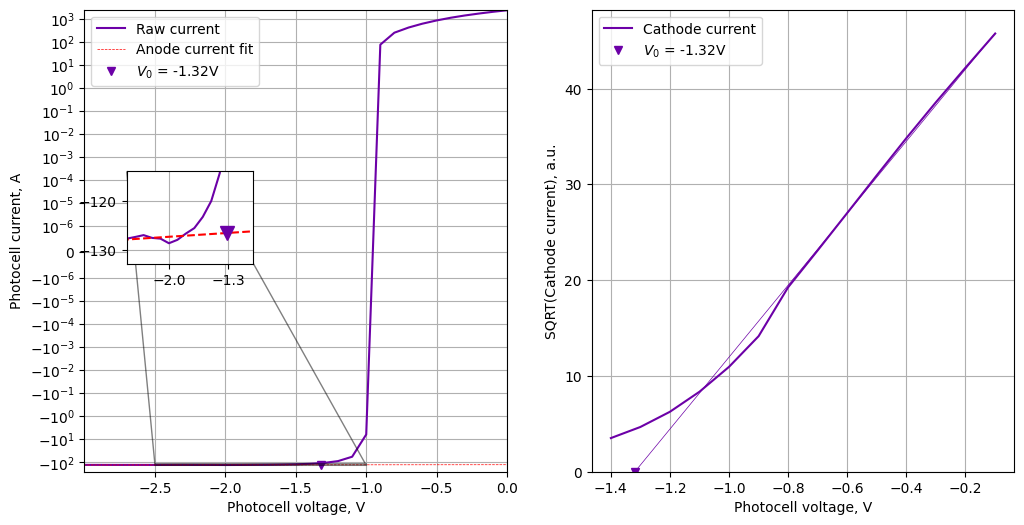

In [27]:
URL = 'https://raw.githubusercontent.com/evgeny-kolonsky/Lab4/refs/heads/main/PE/2026.11/DIY/'
NORMPOINT = 0 #V
ANODE_VMAX = -2.0 #V

# example
fig, ax = plt.subplots(1, 2, figsize=(12,6))
name, wl = 'photoeffect_20261025_151100', 405

color = wavelength_to_color(wl)
url = URL+ f'{name}.csv'
text = request.urlopen(url).read().decode('utf-8').splitlines()
V, I, WL  = np.genfromtxt(text, \
                              delimiter=',', usecols=[6,7,1], skip_header=1, unpack=True)
wls = np.unique(WL)
mask = (WL == wl)
Vm = V[mask]
Im = I[mask]
V0, debug = find_root2(Vm, Im, return_diagnostics=True)
anode_fit = debug['anode_fit']
ax[0].plot(Vm, Im, color=color, label='Raw current')
ax[0].plot(Vm, anode_fit.slope * Vm + anode_fit.intercept, color='red', lw=0.5, ls='--', label='Anode current fit')
ax[0].plot(V0, anode_fit.slope * V0 + anode_fit.intercept, 'v', color=color, label=rf'$V_0$ = {V0:.2f}V')
ax[0].set_xlabel('Photocell voltage, V')
ax[0].set_ylabel('Photocell current, A')
ax[0].grid()
ax[0].set_xlim(-3,0)
ax[0].set_xticks([-2.5, -2, -1.5, -1, -0.5, 0])
ax[0].set_yscale('symlog', linthresh=1e-6)
ax[0].legend()

axins = ax[0].inset_axes([0.1, 0.45, 0.3, 0.2]) # [x, y, width, height] in axes coordinates
axins.plot(Vm, Im, color=color)
axins.plot(Vm, anode_fit.slope * Vm + anode_fit.intercept, color='red', ls='--')
I0 = anode_fit.slope * V0 + anode_fit.intercept
axins.plot(V0, anode_fit.slope * V0 + anode_fit.intercept, 'v', color=color, ms=10)

#axins.set_xlim(-2.5, V0*0.8)
axins.set_xlim(-2.5, -1)
axins.set_ylim(I0*1.05,I0*0.9)
axins.grid(True)
axins.set_xticks([-2.0, -1.3])
#axins.set_yticks([])
ax[0].indicate_inset_zoom(axins, edgecolor="black")

#
on = debug['cathode_mask']
xv, yv, cathode_fit = debug['xv'], debug['yv'], debug['cathode_fit']
ax[1].plot(xv, yv, '-', color=color, label='Cathode current')
ax[1].plot(V0, 0, 'v', color=color, label=rf'$V_0$ = {V0:.2f}V')
ax[1].plot(xv, cathode_fit.slope * xv + cathode_fit.intercept, color=color, lw=0.5)
ax[1].set_xlabel('Photocell voltage, V')
ax[1].set_ylabel('SQRT(Cathode current), a.u.')
ax[1].grid()
ax[1].legend()
ax[1].set_ylim(bottom=0)


0 395.0
1 405.0
2 460.0
3 470.0
4 525.0
5 590.0
6 624.0
photoeffect_20261025_151100 too few cathode points
7 640.0
photoeffect_20261025_151100 too few cathode points


/tmp/ipykernel_2816/664445888.py:58: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax[1].legend()


# wavelength(nm) V0(V) observed(nm) err(nm)
395 1.41 398 8
405 1.32 401 6
460 0.96 469 11
470 1.17 448 8
525 0.62 529 8
590 0.52 590 7



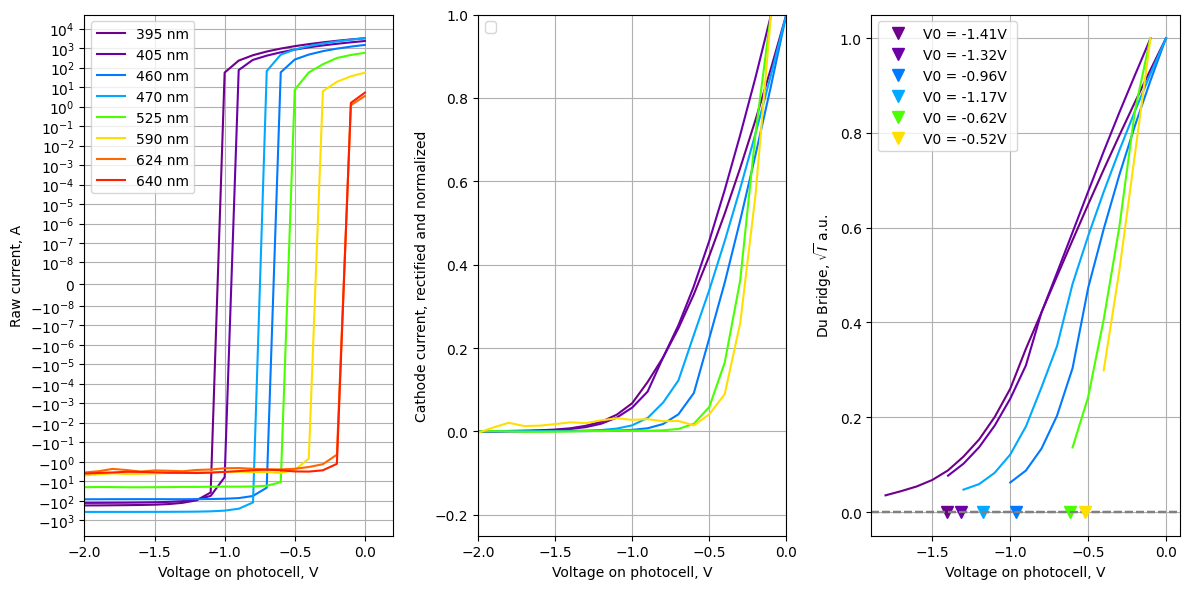

In [29]:
fig, ax = plt.subplots(1, 3, figsize=(12,6))
plt.grid()

data = '# wavelength(nm) V0(V) observed(nm) err(nm)\n'

name = 'photoeffect_20261025_151100'

url = URL+ f'{name}.csv'
text = request.urlopen(url).read().decode('utf-8').splitlines()
V, I, WL  = np.genfromtxt(text, \
                              delimiter=',', usecols=[6, 7, 1], skip_header=1, unpack=True)

for i, wl in enumerate(np.unique(WL)):
  print(i, wl)
  color= wavelength_to_color(wl)
  opacity = 1
  mask = WL==wl
  Im = I[mask]
  Vm = V[mask]

  # (1) Raw VAC

  ax[0].plot(Vm, Im, '-',  color=color, label=f'{wl:.0f} nm')
  ax[0].set_xlabel('Voltage on photocell, V');
  ax[0].set_ylabel('Raw current, A')
  ax[0].set_yscale('symlog', linthresh=1e-8)
  ax[0].set_xlim(left=-2)
  ax[0].legend()
  ax[0].grid(True)

  # (2) остаток = катодный ток
  # Find points where current I crosses zero current line
  V0, d = find_root2(Vm, Im,  return_diagnostics=True)
  if np.isnan(V0):
    print(name, d['reason'])
    continue
  # diagnostics
  R = d['cathode_current']
  on = d['cathode_mask']
  xv, yv = d['xv'], d['yv']
  cathode_fit = d['cathode_fit']

  # fill data
  wl_blue, wl_red = get_observed_by_nominal(wl)
  data += f'{wl:.0f} {-V0:.2f} {wl_blue:.0f} {wl_red:.0f}\n'

  normalization_parameter = np.max(R[Vm <= NORMPOINT])
  Im /= normalization_parameter
  R /= normalization_parameter
  ax[1].plot(Vm, R, '-', ms=2, color=color)
  #ax[1].plot(V0, 0, 'v', ms=8, color=color, label=f'V0 = {V0:.2f}V ')
  #ax[1].axvline(V0, color='#e08000', ls='--', label=f'V0 = {V0:.2f} В')
  ax[1].set_xlim(-2, 0.);
  ax[1].set_ylim(-0.25, 1)
  ax[1].set_xlabel('Voltage on photocell, V');
  ax[1].set_ylabel('Cathode current, rectified and normalized')
  ax[1].grid(True)
  ax[1].legend()

  # (3) Дю-Бридж: sqrt(R) vs V
  xv, yv = d['xv'], d['yv'];
  normalization_parameter = np.max(yv)
  yv /= normalization_parameter
  ax[2].axhline(0, color='gray', ls='--')
  ax[2].plot(V0, 0, 'v', ms=8, color=color, label=f'V0 = {V0:.2f}V ')
  ax[2].plot(xv, yv, '-', ms=2, color=color)
  ax[2].set_xlabel('Voltage on photocell, V');
  ax[2].set_ylabel(r'Du Bridge, $\sqrt{I}$ a.u.')
  ax[2].grid(True)
  ax[2].legend()
plt.tight_layout()

print(data)

In [30]:
data.splitlines()

['# wavelength(nm) V0(V) observed(nm) err(nm)',
 '395 1.41 398 8',
 '405 1.32 401 6',
 '460 0.96 469 11',
 '470 1.17 448 8',
 '525 0.62 529 8',
 '590 0.52 590 7']

# Plank's constant and Work potential determination

$$
 e V_0(\nu) = h \nu -  e W
$$

/tmp/ipykernel_2816/3428120152.py:6: RuntimeWarning: divide by zero encountered in divide
  return c * h/ e / energy  * 1e9


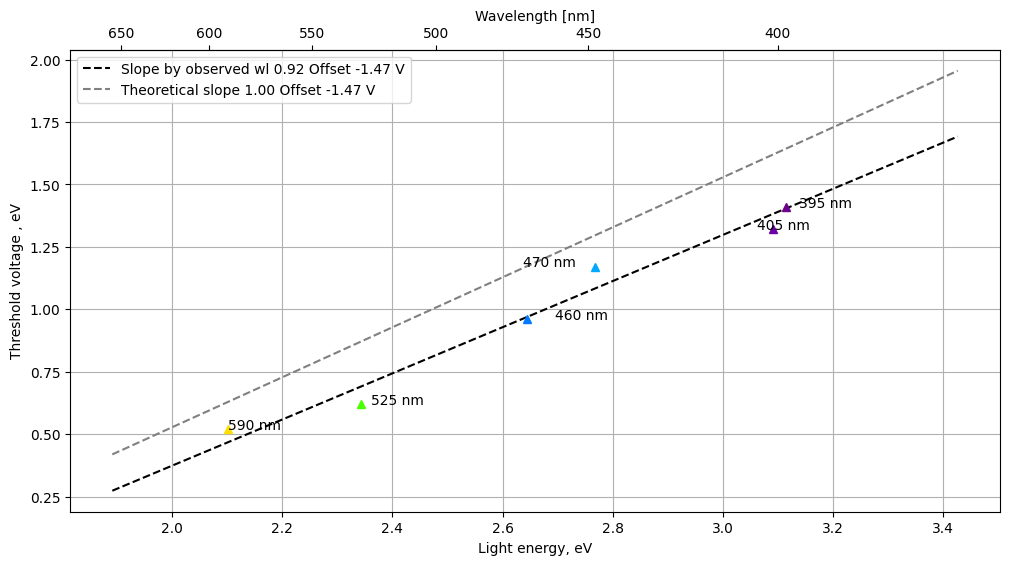

In [36]:
def wl2E(wl):
    return c * h / e / (wl *1e-9)


def E2wl(energy):
    return c * h/ e / energy  * 1e9

fig, ax = plt.subplots(figsize=(12,6))


secax = ax.secondary_xaxis('top', functions=(wl2E, E2wl))
secax.set_xlabel('Wavelength [nm]')


wl_nominal, V0, wl_observed, wl_observed_err = np.genfromtxt(data.splitlines()).T
mask = wl_nominal != 730 # skipping red with bad data
wl_nominal = wl_nominal[mask]
V0 = V0[mask]
wl_observed = wl_observed[mask]
wl_observed_err = wl_observed_err[mask]

energy_observed = h * c / wl_observed * 1e9 / e
energy_observed_err = h * c / wl_observed_err * 1e9 / e

energy_for_fit  = energy_observed
fit = linregress(V0, energy_for_fit)
slope = 1/fit.slope
offset = -fit.intercept / fit.slope
en_dense = np.linspace(np.min(energy_for_fit)*0.9, np.max(energy_for_fit)*1.1)
plt.plot(en_dense, en_dense * slope + offset, color='black', ls='--', \
         label=rf'Slope by observed wl {slope:.2f} Offset {offset:.2f} V')

plt.plot(en_dense, en_dense * 1 + offset, color='gray', ls='--', \
         label=rf'Theoretical slope {1:.2f} Offset {offset:.2f} V')



for i in range(len(V0)):
  # Reshape energy_err[:, i] from (2,) to (2, 1) for asymmetric errors on a single point
  #plt.errorbar(energy_observed[i], V0[i], yerr=0, xerr=energy_err[:, i].reshape((2, 1)), ls='', color=wavelength_to_color(wl_nominal[i]))
  plt.plot( energy_observed_blue[i], V0[i], marker='^', color=wavelength_to_color(wl_nominal[i]))
  plt.annotate(f'{wl_nominal[i]:.0f} nm', (energy_nominal[i], V0[i]))

#plt.plot(en_dense, en_dense , color='lightgray', label=f'Expected slope 1.0')

#for i in range(len(V0)):
#    plt.annotate(f'{wl[i]*1e9:.0f} nm', (V0[i], energy[i]))

plt.grid()
plt.legend()
plt.xlabel(r'Light energy, eV')
plt.ylabel(r'Threshold voltage , eV')
plt.legend()
plt.show()